# Test sinyalleri üretimi

Kendi uyarım (stimulus) sinyalini oluştur, incele ve VHDL testbench'leri ile kart için Q-format dosyaları olarak yaz.

1. **Parametreler** - örnekleme frekansı, uzunluk, kelime formatı, çıkış klasörü.
2. **Sinyalleri tanımla** - `gen_signals.py` içindeki yapı taşlarını birleştir (istediğin gibi düzenle).
3. **İncele** - zaman düzlemi ve spektrum.
4. **Nicemle ve yaz** - `.txt` (işaretli onluk, `textio` için) ve `.hex` (ikiye tümleyen, BRAM başlangıç değeri için).

Yukarıdan aşağıya çalıştır. Normalde sadece 1. ve 2. bölümlerin düzenlenmesi gerekir.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../models")
from gen_signals import (sine, add, scale, dc, gaussian_noise, uniform_noise,
                         step, impulse, square, chirp, to_codes, generate, plot)

## 1. Parametreler

`INT_BITS` işaret bitini de sayar; yani Q2.15, -2.0 .. +1.99997 aralığını 2^-15 adımlarla kapsar.
Standart seti (`python3 gen_signals.py` ile üretilen) ezmemek için `OUT_DIR` olarak `../stimulus` dışında bir klasör kullan.

In [2]:
FS        = 1000.0   # örnekleme frekansı (Hz)
N         = 2048     # her sinyaldeki örnek sayısı
INT_BITS  = 2        # tamsayı bitleri (işaret biti dahil)
FRAC_BITS = 15       # kesirli bitler
SEED      = 1234     # gürültü tohumu: aynı tohum her çalıştırmada aynı gürültüyü verir

OUT_DIR   = "../stimulus_custom"
WRITE     = True     # False = sadece bak, dosya yazma

## 2. Sinyalleri tanımla

Her satır `isim: ondalıklı sayı listesi` biçimindedir. Genlikler gerçek sayılardır (1.0 = Qm.f içinde tam "bir"), bu yüzden **tepe değerini** `2**(INT_BITS-1)` altında tut; aksi halde örnekler doyuma gider (4. bölümde raporlanır).

Yapı taşları: `sine(freq, amp)`, `square(freq, amp)`, `chirp(f0, f1, amp)`, `step(amp, start)`, `impulse(amp, at)`, `dc(level)`, `gaussian_noise(sigma)`, `uniform_noise(amp)`; bunlar `add(...)` ve `scale(x, gain)` ile birleştirilir. Yukarıdaki parametreleri izlemeleri için `n=N, fs=FS` ver.

In [3]:
signals = {
    # standart setle aynı şekiller, artık yukarıdaki FS / N değerlerini izliyor
    "sine_10hz":         sine(10, 1.0, n=N, fs=FS),
    "compound_10_100hz": add(sine(10, 0.8, n=N, fs=FS), sine(100, 0.5, n=N, fs=FS)),
    "noisy_sine_10hz":   add(sine(10, 0.8, n=N, fs=FS), gaussian_noise(0.2, n=N, seed=SEED)),

    # kendi sinyalini oluşturma örnekleri
    "three_tones":       add(sine(5, 0.5, n=N, fs=FS), sine(50, 0.4, n=N, fs=FS), sine(200, 0.3, n=N, fs=FS)),
    "sine_plus_dc":      add(dc(0.5, n=N), sine(20, 0.6, n=N, fs=FS)),
    "noisy_square_5hz":  add(square(5, 0.6, n=N, fs=FS), uniform_noise(0.15, n=N, seed=SEED)),
}

## 3. İncele

Önce zaman düzlemi. Sonra genlik spektrumu; sinyallerin grafiğinden önce ne gösterdiğinin ve grafikte neden pencere kullanıldığının biraz açıklanması gerekiyor.

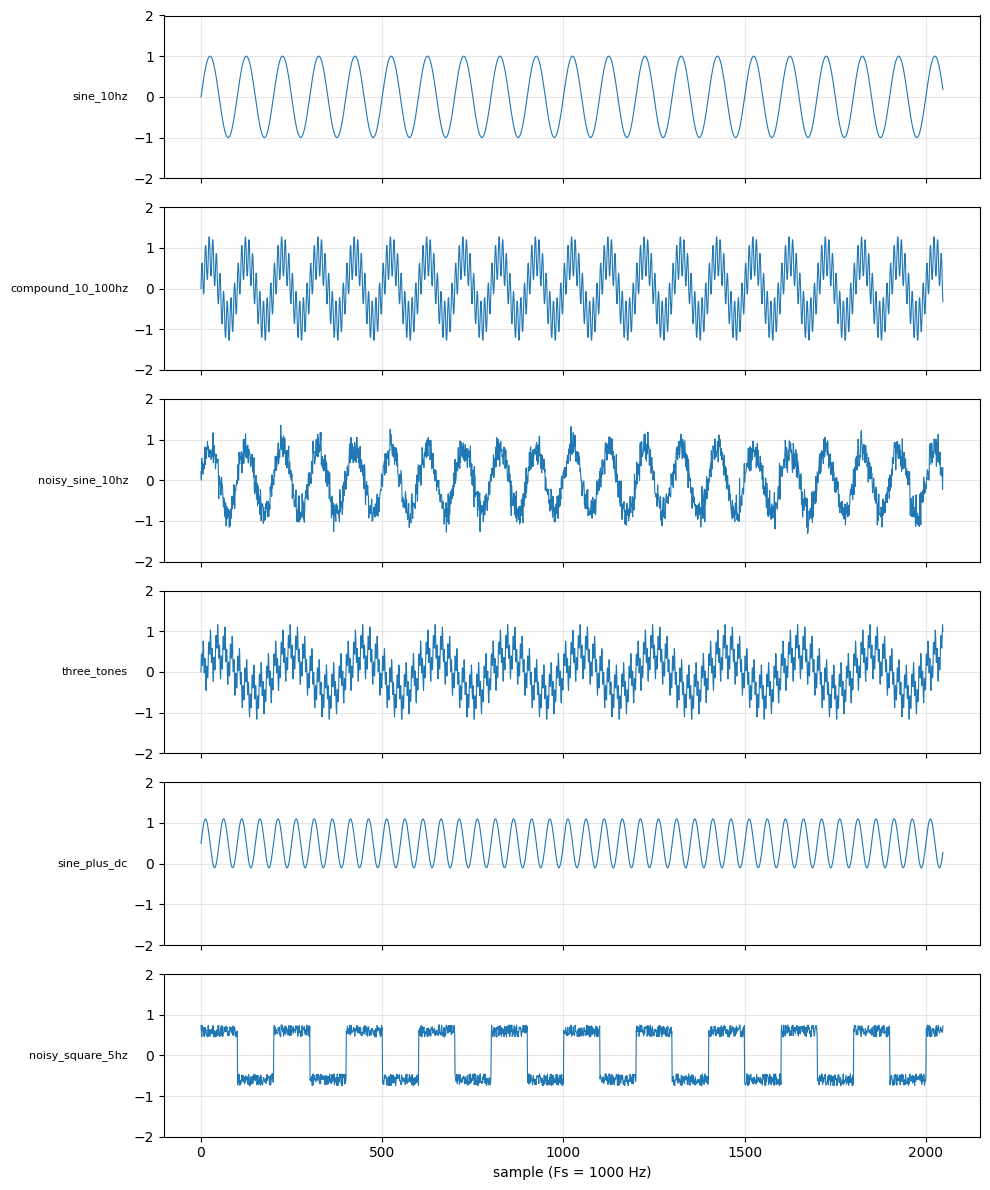

In [4]:
# Sadece bellekte nicemle (dosyalar 4. bölümde yazılır); böylece grafikler donanımın göreceği şeyi aynen gösterir.
codes = {k: to_codes(v, INT_BITS, FRAC_BITS) for k, v in signals.items()}

fig = plot(codes, fs=FS, frac_bits=FRAC_BITS, int_bits=INT_BITS)
plt.show()

### Ton nedir?

**Ton**, tek bir frekansta, sabit genlik ve fazla duran bir sinüstür: $A \sin(2\pi f t + \varphi)$. Bu defterdeki `sine(10, 0.8)`, genliği 0.8 olan 10 Hz'lik bir tondur.

Kelime sesten gelir. Diyapazon ya da ıslık saf bir sinüs dalgası üretir ve kulak bunu tek bir sabit perde, yani bir *ton* olarak duyar. Sinyal işlemede kelime bu anlamıyla kaldı: "ton", tam olarak tek bir frekansı olan şeydir. `two-tone test` (bir sistemin iki sinüsü nasıl karıştırdığını görmek için ikisini birlikte vermek), `pilot ton`, `DTMF tonları` gibi ifadelerde de karşına çıkar.

Ton ile gürültüyü karşılaştırmak işe yarar. Ton, tüm enerjisini tek bir frekansa koyar, bu yüzden spektrumda bir **tepe** olur. Gürültü enerjisini tüm frekanslara yayar, bu yüzden düz bir **taban** olur. Geri kalan her şey (kare dalga, konuşma) tonların bir karışımıdır; spektrumun bu kadar faydalı bir resim olmasının nedeni budur.

### Genlik spektrumunu okumak

Zaman düzlemi grafiği *ne zaman* sorusunu yanıtlar: her anda değerin ne olduğunu. Spektrum ise kaydın *her frekanstan ne kadar* içerdiğini yanıtlar.

**Fikir.** $N$ örneklik herhangi bir kayıt, $0,\ F_s/N,\ 2F_s/N,\ \ldots,\ F_s/2$ frekanslarındaki sinüslerin toplamı olarak yazılabilir. Her frekans için FFT iki sayı verir: o sinüsün ne kadar büyük olduğu (genlik) ve çevriminin neresinde başladığı (faz). **Genlik** spektrumu birincisini tutar, ikincisini atar. Saf bir tonun tek bir tepe olmasının, bir sinyali zamanda kaydırmanın genlik spektrumunu değiştirmemesinin nedeni budur.

**Eksenler**

- **x, frekans.** $k$ noktası $k \cdot F_s/N$ frekansındadır. $F_s = 1000$ ve $N = 2048$ ile noktalar ("bin"ler) 0.488 Hz arayla, 0'dan Nyquist'e ($F_s/2 = 500\ \text{Hz}$) kadar dizilir. Gerçek bir sinyalin ayna görüntüsü olan negatif frekansları ek bilgi taşımaz; bu yüzden `np.fft.rfft` sadece pozitif yarıyı verir: $N/2 + 1 = 1025$ bin.
- **y, dB cinsinden seviye.** Sayıların ne anlama geldiği aşağıdaki hücrede açıklanıyor.

**Ölçek çarpanı** `/ (window.sum() / 2)`, genliği $A$ olan bir sinüsün tepede $A$ okunmasını sağlar. Genliği $A$ olan gerçek bir sinüs aslında $+f$ ve $-f$ frekanslarında genliği $A/2$ olan iki karmaşık üstelden oluşur ve `rfft` sadece $+f$ yarısını tutar; $2$ bu yüzden var. `window.sum()` pencerenin kazancını geri alır (sonraki bölüm). İki sonucu: **DC seviyesi değerinin iki katı okunur** (ayna eşi olmadığı için hiçbir şey bölünmemiştir) ve bir tepenin yüksekliği ancak ton tam bir bin'e oturuyorsa doğrudur (aşağıya bak).

**Nelere bakmalı:** tonlar tepelerdir, gürültü düz bir tabandır, kare dalga kendi frekansındaki bir tepe artı 3x, 5x, 7x... frekanslarındaki daha küçük tepelerdir.

### y eksenindeki sayılar ne anlama geliyor?

Spektrumdaki her nokta tek bir soruyu yanıtlar: *sinyalin bu kısmını yeniden üretmek için bu frekansta ne kadar büyük bir sinüs toplamam gerekir?* y değeri o sinüsün **genliğidir**; 1.0'a göre ölçülür ve desibel olarak ifade edilir:

$$\text{seviye}_{\mathrm{dB}} = 20 \log_{10}\!\left(\frac{\text{genlik}}{1.0}\right)$$

- **0 dB**, genlik 1.0 demektir (-1 ile +1 arasında salınan bir sinüs).
- **Negatif sayılar** 1.0'dan küçüktür ve her 20 dB, 10 kat demektir: $-20\ \text{dB} = 0.1$, $-40\ \text{dB} = 0.01$, $-60\ \text{dB} = 0.001$. Her 6 dB, 2 kat demektir.
- **Neden logaritma?** İlginç aralık çok geniştir. 1.0'daki bir ton ile 0.005'teki bir gürültü tabanı 200 kat farklıdır; doğrusal eksende taban, eksenin üstünde bir çizgiden ibaret kalırdı. dB ile ikisi de aynı grafikte okunur.
- **Neden 10 değil de 20?** Desibel *güç* için tanımlanmıştır: $10 \log_{10}(\text{güç})$. Güç genliğin karesiyle orantılıdır ve $\log(a^2) = 2 \log(a)$, bu yüzden genlikten başlayınca 10, 20 olur.

Tablo bunu sayılara döküyor; VHDL'in göreceği tamsayı kodlarında ne anlama geldiği de dahil (Q2.15, bir LSB = 2^-15):

In [5]:
rows = [("1.0", 1.0), ("0.5", 0.5), ("0.1", 0.1), ("0.01", 0.01), ("0.001", 0.001), ("1 LSB = 2^-15", 2.0 ** -15)]
print(f"{'genlik':>14} {'seviye':>10} {'Q2.15 kod değeri':>22}")
for label, a in rows:
    print(f"{label:>14} {20 * np.log10(a):>7.1f} dB {a * 2 ** FRAC_BITS:>22,.1f}")

        genlik     seviye       Q2.15 kod değeri
           1.0     0.0 dB               32,768.0
           0.5    -6.0 dB               16,384.0
           0.1   -20.0 dB                3,276.8
          0.01   -40.0 dB                  327.7
         0.001   -60.0 dB                   32.8
 1 LSB = 2^-15   -90.3 dB                    1.0


Bir seviyeyi okurken akılda tutulması gereken üç şey:

- **Buradaki 0 dB, donanımın tam ölçeği değil, 1.0 genlik demektir.** Grafik başlığı "yaklaşık dBFS" diyor çünkü Q2.15 tam ölçeği aslında 2.0'dır; gerçek dBFS 6 dB daha düşük okurdu. Spektrum sadece sinyale bakmak içindir, dosyaları etkilemez.
- **Bir LSB yaklaşık -90 dB'dir.** -90 dB civarındaki bir özellik nicemleme adımı kadardır. Bundan çok daha düşük bir şey, Q2.15 sinyalinin gerçek bir özelliği olamaz; yuvarlama ya da hesaplamadan gelen sayısal gürültüdür. Aşağıdaki tüm sinyaller grafiğinin -100 dB'de bitmesinin nedeni budur.
- **Gürültü için sayı, gürültü genliği değil bin başına seviyedir.** Sigma = 0.2 olan Gauss gürültüsünün zaman düzleminde rms değeri 0.2'dir (-14 dB) ama enerjisi 1025 bin arasında paylaşılır; bu yüzden her bin sadece yaklaşık -42 dB gösterir. Dolayısıyla taban $N$'e de bağlıdır (aşağıdaki "her grafik ne göstermeli" bölümüne bak).

### Bin nedir?

FFT mümkün olan her frekansı ölçmez. Cetveldeki çizgiler gibi eşit aralıklı $N/2 + 1$ belirli frekansı ölçer. Her çizgi bir **bin**'dir. $k$ numaralı bin tek bir soruyu yanıtlar: *bu kayıtta $k \cdot F_s/N$ frekansından ne kadar var?* FFT'yi, her biri kendi frekansına ayarlı bir dizi dedektör gibi düşün.

**Çizgiler neden $F_s/N$ arayla?** Kayıt $T = N/F_s$ saniye sürer (burada 2.048 s). Kayda *tam sayıda* çevrim sığan tek sinüsler $1/T,\ 2/T,\ 3/T,\ \ldots$ Hz'dekilerdir ve FFT'nin test ettiği frekanslar tam olarak bunlardır. Yani aralık $1/T = F_s/N = 0.488\ \text{Hz}$'dir.

Bundan çıkanlar:

- **Çözünürlük örnekleme frekansından değil, kayıt uzunluğundan gelir.** Birbirinden 1 Hz uzaktaki iki tonu ayırt etmek için en az yaklaşık bir saniyelik kayıt gerekir (pencereyle biraz daha fazla). Daha hızlı örneklemek bir şey katmaz; daha uzun kayıt almak yardımcı olur.
- **Aralık örnekleme frekansından gelir.** Son bin $F_s/2$'dedir (aşağıdaki örtüşme bölümüne bak).
- **Çizgiye oturmayan bir ton, iki yanındaki bin'ler tarafından, biraz da diğer hepsi tarafından görülür.** 10 Hz'lik ton 20.48 çevrim uzunluğundadır; bu, 20. ile 21. çizgi arasındadır. Pencere bölümündeki her şeyin kökü budur.

In [6]:
T = N / FS
print(f"kayıt süresi T = N/Fs = {T:.3f} s  ->  bin aralığı 1/T = Fs/N = {FS / N:.4f} Hz   ({N // 2 + 1} bin, {FS / 2:.0f} Hz'e kadar)\n")

tone = 10.0
print(f"{tone:g} Hz'lik ton kayıtta {tone * T:.2f} çevrim tamamlar\n")
print(f"{'bin k':>6} {'bin frek. (Hz)':>14} {'kayıttaki çevrim':>30} {'tona uzaklık (bin)':>30}")
for k in range(19, 23):
    fk = k * FS / N
    print(f"{k:>6} {fk:>14.3f} {k:>30d} {(tone - fk) / (FS / N):>+30.2f}")

kayıt süresi T = N/Fs = 2.048 s  ->  bin aralığı 1/T = Fs/N = 0.4883 Hz   (1025 bin, 500 Hz'e kadar)

10 Hz'lik ton kayıtta 20.48 çevrim tamamlar

 bin k bin frek. (Hz)               kayıttaki çevrim             tona uzaklık (bin)
    19          9.277                             19                          +1.48
    20          9.766                             20                          +0.48
    21         10.254                             21                          -0.52
    22         10.742                             22                          -1.52


### Neden pencere?

FFT, verdiğin $N$ örneğin **sonsuza kadar tekrar eden bir sinyalin tek periyodu** olduğunu sessizce varsayar. Kayıtta tam sayıda çevrim varsa kopyalar düzgünce birleşir. Yoksa kaydın sonu kendi başına uymaz ve tekrar eden sinyalde her birleşim yerinde bir **sıçrama** olur.

Burada $10\ \text{Hz} \times 2.048\ \text{s} = 20.48$ çevrim var, yani sıçrama *var*. Sıçrama keskin bir kenardır ve keskin kenar tüm frekanslarda enerji içerir. Böylece tek bir temiz 10 Hz tonu, tepe *artı diğer her bin'e yayılan bir etek* olarak görünür. Buna **spektral sızıntı** denir ve asıl görmek istediğin küçük şeyleri (gürültü tabanı, zayıf ikinci ton) gömer.

**Pencere** bunu, kaydı iki ucunda sıfıra inen yumuşak bir çanla çarparak düzeltir; böylece sıçrayacak bir şey kalmaz. Grafikte Hann penceresi kullanılır: $w[n] = 0.5\left(1 - \cos\frac{2\pi n}{N-1}\right)$. Sonraki hücre iki etkiyi gösterir: zaman düzlemindeki birleşim yerleri (üstte) ve bunların spektruma etkisi (altta).

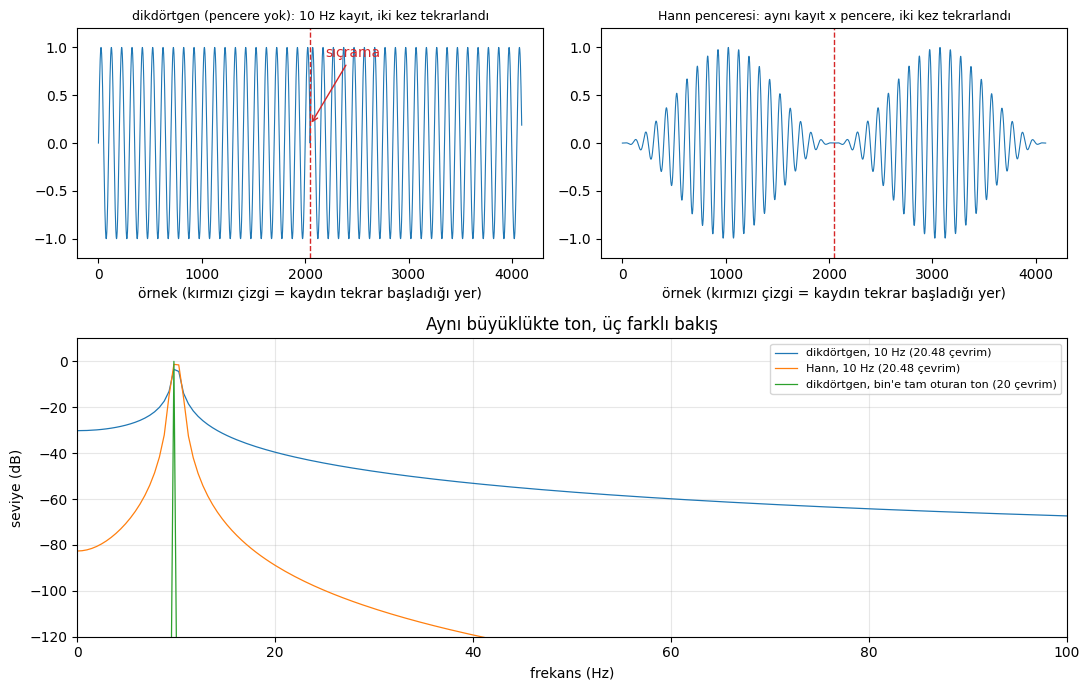

                                            tepe okuması     >5 Hz uzakta
dikdörtgen, 10 Hz (20.48 çevrim)            0.670 (-3.5 dB)     -28.3 dB
Hann, 10 Hz (20.48 çevrim)                  0.860 (-1.3 dB)     -71.3 dB
dikdörtgen, bin'e tam oturan ton (20 çevrim)  1.000 (+0.0 dB)    -240.0 dB


In [7]:
n = np.arange(N)
t = n / FS
f_odd = 10.0                   # kayıtta 20.48 çevrim: kendi üzerine kapanmaz
f_exact = 20 * FS / N          # tam 20 çevrim: tam olarak 20. bine oturur
hann = np.hanning(N)
rect = np.ones(N)

x_odd = np.sin(2 * np.pi * f_odd * t)
x_exact = np.sin(2 * np.pi * f_exact * t)

def mag(x, w):
    return np.abs(np.fft.rfft(x * w)) / (w.sum() / 2)

fq = np.fft.rfftfreq(N, d=1 / FS)
db = lambda a: 20 * np.log10(a + 1e-12)

fig = plt.figure(figsize=(11, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.3])

for col, (title, y) in enumerate([("dikdörtgen (pencere yok): 10 Hz kayıt, iki kez tekrarlandı", x_odd),
                                  ("Hann penceresi: aynı kayıt x pencere, iki kez tekrarlandı", x_odd * hann)]):
    ax = fig.add_subplot(gs[0, col])
    ax.plot(np.arange(2 * N), np.tile(y, 2), lw=0.8)
    ax.axvline(N, color='tab:red', ls='--', lw=1)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('örnek (kırmızı çizgi = kaydın tekrar başladığı yer)')
    ax.set_ylim(-1.2, 1.2)
    if col == 0:
        ax.annotate('sıçrama', xy=(N, x_odd[-1]), xytext=(N + 150, 0.9), color='tab:red',
                    arrowprops=dict(arrowstyle='->', color='tab:red'))

ax = fig.add_subplot(gs[1, :])
curves = [("dikdörtgen, 10 Hz (20.48 çevrim)", mag(x_odd, rect), 'tab:blue'),
          ("Hann, 10 Hz (20.48 çevrim)", mag(x_odd, hann), 'tab:orange'),
          ("dikdörtgen, bin'e tam oturan ton (20 çevrim)", mag(x_exact, rect), 'tab:green')]
for label, s, color in curves:
    ax.plot(fq, db(s), lw=0.9, label=label, color=color)
ax.set_xlim(0, 100)
ax.set_ylim(-120, 10)
ax.set_xlabel('frekans (Hz)')
ax.set_ylabel('seviye (dB)')
ax.grid(alpha=0.3)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('Aynı büyüklükte ton, üç farklı bakış')
fig.tight_layout()
plt.show()

print(f"{'':42} {'tepe okuması':>13} {'>5 Hz uzakta':>16}")
for label, s, _ in curves:
    k = s.argmax()
    away = db(s[np.abs(fq - fq[k]) > 5]).max()
    print(f"{label:42} {s[k]:>6.3f} ({db(s[k]):+.1f} dB) {away:>9.1f} dB")

Demonun gösterdiği (test tonunun genliği üçünde de tam 1.0):

| | tepe okuması | tepeden uzakta en güçlü sızıntı | ana lob genişliği |
|---|---|---|---|
| dikdörtgen, 20.48 çevrim | 0.67 (-3.5 dB) | yaklaşık -28 dB ve etek yavaş azalır | dar (yaklaşık 2 bin) |
| **Hann**, 20.48 çevrim | 0.86 (-1.3 dB) | yaklaşık -71 dB ve hızla söner | daha geniş (yaklaşık 4 bin) |
| dikdörtgen, 20 çevrim (bin'e tam oturan) | 1.00 (0 dB) | hiç: kayıt kendi üzerine kapanır | dar |

- **Pencerenin amacı sızıntıdır.** Pencere olmadan, birim bir ton grafik boyunca yaklaşık -28 dB'lik bir etek bırakır ve `noisy_sine_10hz`'nin gürültü tabanı (yaklaşık -42 dB) onun altında kalırdı. Hann ile etek 40 dB daha düşüktür, bu yüzden taban görünür kalır.
- **Bedeli çözünürlüktür.** Pencere her tonu daha fazla bin'e yayar (Hann: yaklaşık iki kat geniş). Birkaç bin'den yakın iki ton birleşir. Test sinyallerindeki tonlar birbirinden uzak olduğu için Hann burada bir şeye mal olmaz.
- **Bin'e oturmayan bir tonun tepesi düşük okunur.** Ton iki bin'in arasında durur ve hiçbiri tam yüksekliği göstermez (*tarak kaybı - scalloping*: dikdörtgen için en çok -3.9 dB, Hann için en çok -1.4 dB). Bu yüzden `compound_10_100hz` içindeki genliği 0.8 olan 10 Hz'lik ton 0.80 değil, yaklaşık 0.69 okunur. *Sinyal* tamamen doğrudur; sadece grafik sapar.
- **Tepe yüksekliklerinin tam olmasını istiyorsan**, tonu tam sayıda çevrime sığdır: frekansı $k \cdot F_s/N$ olarak seç ya da $N$'i periyodun katı seç ($N = 2000$, 1 kHz'de 10 Hz'in tam 20 çevrimini verir). O zaman dikdörtgen pencere bile temizdir; yeşil eğri bunu gösteriyor.
- **Pencere sadece çizim için uygulanır.** `.txt` ve `.hex` dosyaları ham, pencerelenmemiş örnekleri içerir.

### Tek bir bin'den bakmak: pencere gerçekte neyi değiştirir

Bir bin'i tek bir frekansa ayarlı bir dedektör say; örneğin 20. bin (9.77 Hz). Şimdi birim bir tonu frekans ekseni boyunca kaydır ve sor: *bu dedektör ne kadar güçlü yanıt veriyor?* Bu eğri **bin'in yanıtıdır** ve pencerenin ne yaptığını görmenin en net yoludur. (Pencere sinyali değiştirmez. Her dedektörün şeklini değiştirir.)

- **Pencere yok (dikdörtgen):** her iki yanda bir bin genişliğinde bir tepe ve ardından yavaş sönen dalgalanmalar (*yan loblar*). İlk dalgalanma tepenin sadece yaklaşık -13 dB altındadır. Uzaktaki güçlü bir ton bile bu dalgalanmalar yoluyla bu bin'e biraz sızar: **sızıntı budur**.
- **Hann penceresi:** tepe yaklaşık iki kat geniştir (her iki yanda iki bin'e uzanır) ama dalgalanmalar yaklaşık -31 dB'de başlar ve hızla düşer. Uzaktaki tonlar neredeyse hiç görünmez.
- **İki çizginin tam ortasında** (merkezden 0.5 bin uzakta) dedektör tonu azalmış yükseklikte görür: dikdörtgen için yaklaşık -4 dB, Hann için yaklaşık -1.4 dB. Bu, önceki bölümdeki **tarak kaybıdır (scalloping)**.

Yani pencere bir takastır: daha geniş bir tepe (çözünürlük azalır; iki yakın ton birleşir) karşılığında çok daha düşük uzak sızıntı ve bin'ler arasında daha düz bir yanıt. Bir grafikte tonları ve gürültü tabanını bulmak için bu takas neredeyse her zaman değer.

dikdörtgen (pencere yok) merkezden 0.5 bin uzakta: -3.8 dB   en yüksek yan lob: -13.0 dB
Hann                     merkezden 0.5 bin uzakta: -1.4 dB   en yüksek yan lob: -31.5 dB


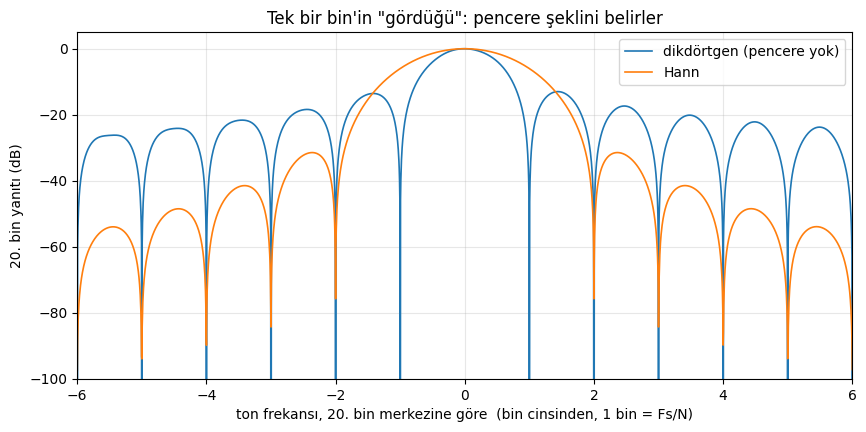

In [8]:
k0 = 20
nn = np.arange(N)
kern = np.exp(-2j * np.pi * k0 * nn / N)            # 20. bine ayarlı "dedektör"
d = np.linspace(-6, 6, 2401)                        # tonun 20. bine göre konumu (bin cinsinden)
tones = np.sin(2 * np.pi * (k0 + d)[:, None] * nn / N)

fig, ax = plt.subplots(figsize=(10, 4.5))
for label, w in (("dikdörtgen (pencere yok)", np.ones(N)), ("Hann", np.hanning(N))):
    resp = np.abs((tones * w * kern).sum(axis=1)) / (w.sum() / 2)
    ax.plot(d, 20 * np.log10(resp + 1e-12), label=label, lw=1.2)
    half = 20 * np.log10(resp[np.argmin(np.abs(d - 0.5))])
    side0 = 1.0 if 'dikdörtgen' in label else 2.0
    side = 20 * np.log10(resp[np.abs(d) > side0 + 0.05].max())
    print(f"{label:24} merkezden 0.5 bin uzakta: {half:+.1f} dB   en yüksek yan lob: {side:.1f} dB")
ax.set_xlim(-6, 6)
ax.set_ylim(-100, 5)
ax.set_xlabel('ton frekansı, 20. bin merkezine göre  (bin cinsinden, 1 bin = Fs/N)')
ax.set_ylabel('20. bin yanıtı (dB)')
ax.set_title('Tek bir bin\'in "gördüğü": pencere şeklini belirler')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Grafikteki iki ayrıntı:

- **İki eğri de bin'e tam sayı uzaklıklarda sıfıra değer** (dikdörtgen ±1, ±2, ±3 …; Hann ±2, ±3 …). Başka bir bin'e tam oturan, tam sayıda çevrimli bir ton bu bin'e görünmezdir. Bin'e tam oturan bir tonun temiz bir sonuç vermesinin nedeni budur: pencere yokken tek bir tepe; Hann ile üç bin (merkez 0 dB'de, iki komşusu -6 dB'de) ve başka hiçbir şey.
- **Çentiklerin arasında dalgalanmalar vardır ve dalgalanmalar sızıntıdır.** Bin'e oturmayan bir ton bir dalgalanmanın üzerine düşer. Dikdörtgen dalgalanmaları yüksek kalır (-13 dB ve sonra yavaşça düşer, 6 bin uzakta hâlâ yaklaşık -25 dB). Hann dalgalanmaları 20 ila 40 dB daha düşüktür ve düşmeye devam eder; gürültü tabanını görünür tutan budur.

### Her sinyalin spektrumu (Hann penceresi)

Yukarıdakiyle aynı hesap, her bir sinyaline uygulanmış.

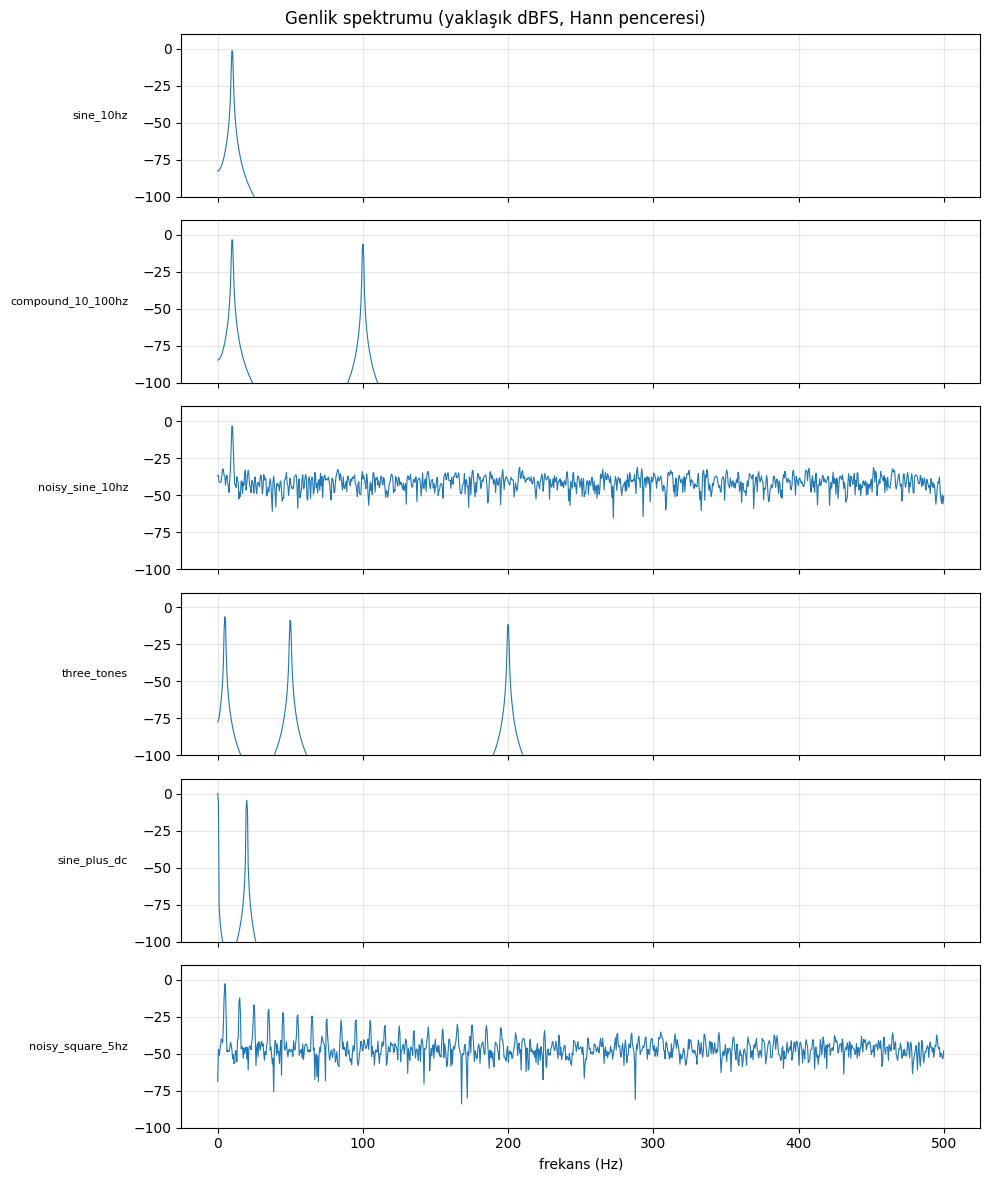

In [9]:
fig, axes = plt.subplots(len(codes), 1, figsize=(10, 2 * len(codes)), sharex=True, squeeze=False)
freqs = np.fft.rfftfreq(N, d=1 / FS)
window = np.hanning(N)
for ax, (name, c) in zip(axes[:, 0], codes.items()):
    x = np.array(c) / 2**FRAC_BITS
    spec = np.abs(np.fft.rfft(x * window)) / (window.sum() / 2)
    ax.plot(freqs, 20 * np.log10(spec + 1e-12), lw=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
    ax.set_ylim(-100, 10)
    ax.grid(alpha=0.3)
axes[-1, 0].set_xlabel("frekans (Hz)")
fig.suptitle("Genlik spektrumu (yaklaşık dBFS, Hann penceresi)")
fig.tight_layout()
plt.show()

Her grafik ne göstermeli:

- **Tonlar:** her tonun frekansında bir tepe; yüksekliği $\approx \text{genlik}$ (ton bin'e oturmuyorsa yukarıda açıklandığı gibi biraz düşük).
- **`noisy_sine_10hz`, `noisy_square_5hz`:** düz bir taban. Seviyesi sadece gürültü genliğine değil $N$'e de bağlıdır: $N$ her iki katına çıktığında bin genişliği yarıya iner, her bin gürültü gücünün yarısını yakalar ve taban 3 dB düşer; tonlar yüksekliğini korur. Sigma = 0.2 olan Gauss gürültüsünün tabanı $N = 2048$'de yaklaşık -42 dB, $N = 4096$'da yaklaşık -45 dB'dir.
- **`sine_plus_dc`:** 0 Hz'de, DC seviyesinin iki katı okunan bir tepe (0.5, 1.0 okunur); nedeni en üstte verildi.
- **`noisy_square_5hz`:** 5, 15, 25 Hz... frekanslarında tepeler (tek harmonikler), 1/k ile azalır.
- **Yaklaşık -100 dB'nin altındaki her şey** grafiğin altında kesilir (`set_ylim(-100, 10)`).

### Kare dalganın neden harmonikleri var?

Yukarıdaki `noisy_square_5hz`'ye bak. 5 Hz'lik bir kare dalga, ama spektrumda 5, 15, 25, 35 Hz... frekanslarında tepeler var. Bu fazladan tepeler **harmoniklerdir**: tekrar frekansının tam katlarındaki ($f_0,\ 2f_0,\ 3f_0,\ \ldots$) sinüsler. Bir yapay etki ya da gürültü değildirler. Gürültü sadece onların altındaki tabanı yükseltir.

**Neden var olmak zorundalar.** Sinüs yumuşak ve yuvarlaktır. Kare dalganın düz tepeleri ve dikey kenarları vardır. $f_0$'daki tek bir sinüs genel iniş çıkışı izleyebilir ama düz kısmı aşar ve köşeyi yapamaz. $3f_0$'daki daha küçük bir sinüs eklemek tepeyi düzeltir ve kenarı dikleştirir; sonra $5f_0$'daki artakalanı düzeltir, böyle devam eder. Kenar ne kadar keskinse o kadar çok sinüs gerekir ve spektrumun gösterdiği tam olarak budur. (Fourier'in sonucu: tekrar eden her şekil, tekrar frekansının katlarındaki sinüslerin toplamıdır.)

**Neden sadece tek olanlar.** Kare dalga periyodunun ikinci yarısı, birinci yarısının ters çevrilmişidir: $x(t + T/2) = -x(t)$. $k$ numaralı harmonikteki bir sinüs yarım periyot kaydırılınca $(-1)^k$ ile çarpılır. Çift $k$ için *değişmeden* geri gelir; bu yüzden çift harmoniklerin hiçbir birleşimi işaret değiştiren bir sinyal üretemez. Tek harmonikler işaret değiştirir, bu yüzden sadece onlar görünür.

**Neden $1/k$ ile küçülürler.** Her tek harmoniğin genliği $\frac{4A}{\pi k}$'dır. $A = 0.6$ için bu, $f_0$'da 0.764 (-2.3 dB), $3f_0$'da 0.255 (-11.9 dB), $5f_0$'da 0.153 (-16.3 dB)... olur. Kenardaki sıçrama, serinin sadece $1/k$ ile düşmesinin sebebidir; bu yavaştır: bir kare dalganın çok sayıda harmoniğe ihtiyacı vardır ve filtrelenirse kenarlarının çınlamasının nedeni budur. Sonraki hücre kare dalgayı harmoniklerinden yeniden kurar ve genlikleri formülle karşılaştırır.

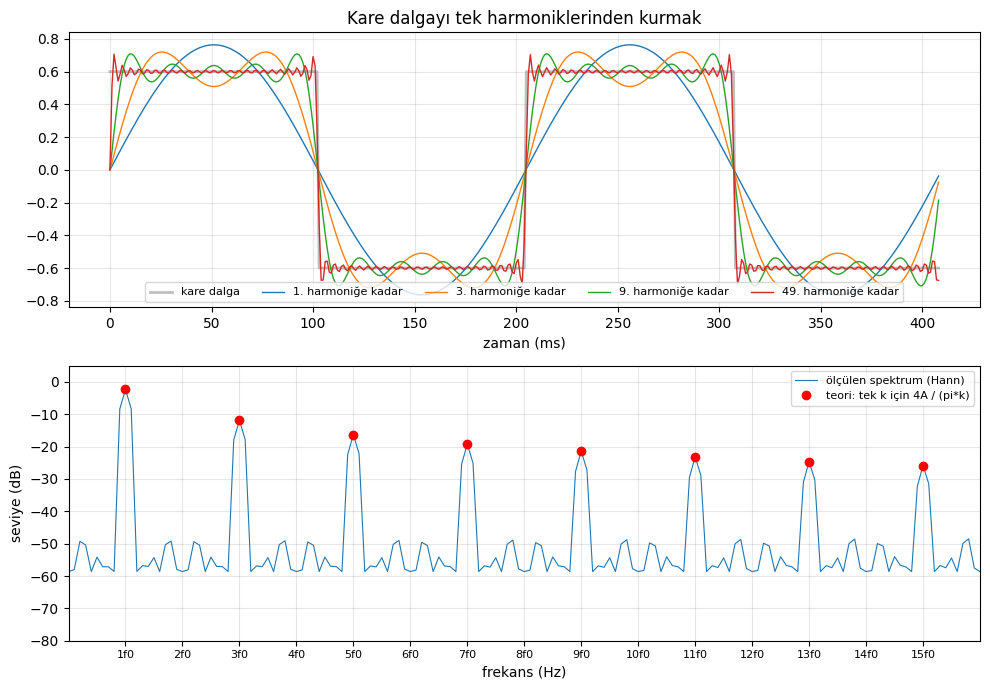

  k    teori   ölçülen    seviye
  1   0.7639    0.7639   -2.3 dB
  2   0.0000    0.0013  -58.0 dB
  3   0.2546    0.2546  -11.9 dB
  4   0.0000    0.0013  -57.9 dB
  5   0.1528    0.1528  -16.3 dB
  6   0.0000    0.0013  -57.9 dB
  7   0.1091    0.1091  -19.2 dB
  8   0.0000    0.0013  -57.8 dB
  9   0.0849    0.0849  -21.4 dB
 10   0.0000    0.0013  -57.7 dB
 11   0.0694    0.0694  -23.2 dB


In [10]:
f0 = 10 * FS / N                 # kayıtta tam 10 çevrim; böylece her harmonik bir bine oturur
A = 0.6
sq = np.array(square(f0, A, n=N, fs=FS))
t = np.arange(N) / FS

def partial_sum(max_harmonic):
    y = np.zeros(N)
    for k in range(1, max_harmonic + 1, 2):                       # sadece tek harmonikler
        y += 4 * A / (np.pi * k) * np.sin(2 * np.pi * k * f0 * t)
    return y

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))

two_periods = int(2 * FS / f0)
ax1.plot(t[:two_periods] * 1000, sq[:two_periods], color='gray', lw=2, alpha=0.5, label='kare dalga')
for h in (1, 3, 9, 49):
    ax1.plot(t[:two_periods] * 1000, partial_sum(h)[:two_periods], lw=1, label=f'{h}. harmoniğe kadar')
ax1.set_xlabel('zaman (ms)')
ax1.set_title('Kare dalgayı tek harmoniklerinden kurmak')
ax1.legend(fontsize=8, ncol=5, loc='lower center')
ax1.grid(alpha=0.3)

w = np.hanning(N)
spec = np.abs(np.fft.rfft(sq * w)) / (w.sum() / 2)
fq = np.fft.rfftfreq(N, d=1 / FS)
ax2.plot(fq, 20 * np.log10(spec + 1e-12), lw=0.8, label='ölçülen spektrum (Hann)')
hs = np.arange(1, 16, 2)
ax2.plot(hs * f0, 20 * np.log10(4 * A / (np.pi * hs)), 'ro', label='teori: tek k için 4A / (pi*k)')
ax2.set_xlim(0, 16 * f0)
ax2.set_ylim(-80, 5)
ax2.set_xlabel('frekans (Hz)')
ax2.set_ylabel('seviye (dB)')
ax2.set_xticks([k * f0 for k in range(1, 16)], [f'{k}f0' for k in range(1, 16)], fontsize=8)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"{'k':>3} {'teori':>8} {'ölçülen':>9} {'seviye':>9}")
for k in range(1, 12):
    meas = spec[10 * k - 1:10 * k + 2].max()
    th = 4 * A / (np.pi * k) if k % 2 else 0.0
    print(f"{k:>3} {th:>8.4f} {meas:>9.4f} {20 * np.log10(meas + 1e-12):>6.1f} dB")

Sonucu okumak:

- Üstteki grafik inşayı gösterir: sadece 1. harmonik bir sinüstür, 3'ü eklemek tepeyi düzleştirir ve 49'a gelince kenarlar neredeyse dikeydir. Kenarın yanındaki küçük taşma, kaç harmonik eklenirse eklensin hiç gitmez (*Gibbs* etkisi, sıçramanın yaklaşık %9'u).
- Alttaki grafikte kırmızı noktalar formül, mavi eğri ölçümdür. Her tek harmonikte uyuşurlar.
- **Çift harmonikler ölçümde tam sıfır değildir** (tek olanlar -2 ile -20 dB iken yaklaşık -58 dB). Teoride tamamen sönerler; burada örneklenen kenarlar örneklerin arasına düştüğü için yarım periyot simetrisini çok az bozar.
- **Gürültü bir harmonik değildir.** `noisy_square_5hz` içinde düzgün dağılımlı gürültü sadece tabanı yaklaşık -49 dB'ye yükseltir. Harmonikler bu tabanın üstünde oldukları sürece görünür kalır.
- **Örtüşme uyarısı:** gerçek bir kare dalganın harmonikleri sonsuza kadar uzanır ama 1 kHz'de örneklemek sadece 500 Hz'e kadarki frekansları temsil edebilir. Bunun ötesindeki harmonikler grafiğe geri katlanır ve zaten bir harmoniği olan bin'lere eklenir; bu yüzden en yüksekler biraz sapmış okunur.

### Örtüşme (aliasing) ve Nyquist sınırı ($F_s/2$)

Örnekleme sinyale sadece birbirinden $1/F_s$ uzaktaki anlarda bakar. Bir sinüsü temsil etmek için çevrim başına en az iki örnek gerekir; bu yüzden örneklenmiş bir sinyalin tutabileceği en yüksek frekans **$F_s/2$, yani Nyquist frekansıdır**. Burada bu $1000 / 2 = 500\ \text{Hz}$'dir; her spektrum grafiğinin sağ kenarı.

Bunun üstünde frekanslar artık ayırt edilemez. $f$ frekansındaki bir ton ile $F_s - f$ frekansındaki bir ton aynı örnekleri üretir, $F_s + f$ de öyle. Ton kaybolmaz: $0 \ldots F_s/2$ bandına **geri katlanır**:

$$f_{\mathrm{alias}} = \left| f - F_s \cdot \operatorname{round}\!\left(\frac{f}{F_s}\right) \right|$$

$F_s = 1\ \text{kHz}$'de: 600 Hz, 400 Hz'de; 900 Hz, 100 Hz'de; 1100 Hz, 100 Hz'de görünür. Frekans eksenini $F_s/2$, $F_s$, $3F_s/2$, … noktalarından akordeon gibi katlanmış hayal et.

Aşağıdaki hücre bunu gösterir. Üst: 100 Hz'lik ve 1100 Hz'lik ton farklı dalgalardır ama 1 kHz örneklemede her örnek aynı değere düşer. Alt: üretilmiş bir `sine(600)`'ün spektrum tepesi gerçekten 400 Hz'dedir.

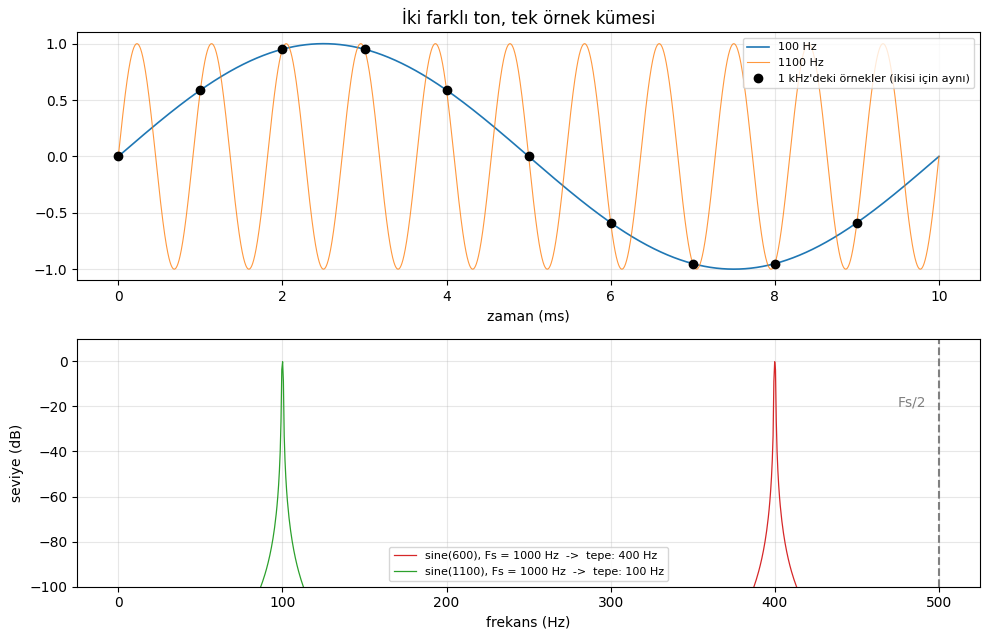

 giriş (Hz) ->     görünür (Hz)
        100 ->              100
        400 ->              400
        450 ->              450
        600 ->              400
        900 ->              100
       1100 ->              100
       1900 ->              100

tam Fs/2'de örnekler faza bağlıdır ve tamamen sıfırlanabilir:
  faz   0 derece:  [ 0.  0. -0.  0. -0.  0.]
  faz  45 derece:  [ 0.707 -0.707  0.707 -0.707  0.707 -0.707]
  faz  90 derece:  [ 1. -1.  1. -1.  1. -1.]


In [11]:
tt = np.linspace(0, 0.010, 4000)                # "sürekli" zaman, ilk 10 ms
ts = np.arange(10) / FS                         # Fs = 1 kHz'deki örnekleme anları

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5))
ax1.plot(tt * 1000, np.sin(2 * np.pi * 100 * tt), label='100 Hz', lw=1.2)
ax1.plot(tt * 1000, np.sin(2 * np.pi * 1100 * tt), label='1100 Hz', lw=0.8, alpha=0.8)
ax1.plot(ts * 1000, np.sin(2 * np.pi * 100 * ts), 'ko', label="1 kHz'deki örnekler (ikisi için aynı)")
ax1.set_xlabel('zaman (ms)')
ax1.set_title('İki farklı ton, tek örnek kümesi')
ax1.legend(fontsize=8, loc='upper right')
ax1.grid(alpha=0.3)

w = np.hanning(N)
fq = np.fft.rfftfreq(N, d=1 / FS)
for f_in, color in ((600, 'tab:red'), (1100, 'tab:green')):
    x = np.array(sine(f_in, 1.0, n=N, fs=FS))
    s = np.abs(np.fft.rfft(x * w)) / (w.sum() / 2)
    ax2.plot(fq, 20 * np.log10(s + 1e-12), lw=0.9, color=color, label=f'sine({f_in}), Fs = {FS:g} Hz  ->  tepe: {fq[s.argmax()]:.0f} Hz')
ax2.axvline(FS / 2, color='gray', ls='--')
ax2.text(FS / 2 - 8, -20, 'Fs/2', ha='right', color='gray')
ax2.set_ylim(-100, 10)
ax2.set_xlabel('frekans (Hz)')
ax2.set_ylabel('seviye (dB)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
fig.tight_layout()
plt.show()

alias = lambda f: abs(f - FS * round(f / FS))
print(f"{'giriş (Hz)':>11} -> {'görünür (Hz)':>16}")
for f in (100, 400, 450, 600, 900, 1100, 1900):
    print(f"{f:>11} -> {alias(f):>16.0f}")

print("\ntam Fs/2'de örnekler faza bağlıdır ve tamamen sıfırlanabilir:")
for phase in (0, np.pi / 4, np.pi / 2):
    print(f"  faz {np.degrees(phase):>3.0f} derece: ", np.round(np.sin(2 * np.pi * (FS / 2) * np.arange(6) / FS + phase), 3))

**Neden önemsemelisin**

1. **Geri alınamaz.** Örneklemeden sonra örtüşmüş bir bileşen, alt frekanstaki gerçek bir tondan ayırt edilemez. Hiçbir sayısal işleme bunları ayıramaz; `dsp03`'teki EMA filtresi de dahil: filtreye göre katlanmış ton bant içi bir sinyaldir.
2. **Donanımda, ADC girişinde $F_s/2$'nin üstündeki her şey bandına katlanır.** Girişim, gürültü ve harmonikler hepsi öyle. Bu yüzden bir ADC'nin önünde, kesim frekansı $F_s/2$'nin güvenli biçimde altında olan analog bir **örtüşme önleyici (anti-alias) alçak geçiren filtre** olmalıdır. Aynı kural örnekleme frekansını sonradan düşürürken de geçerlidir (decimation, örneğin bir lock-in filtre zincirinde): *önce* alçak geçir, *sonra* örnekleri at.
3. **Bu test sinyallerinde sessizce olur.** $F_s = 1\ \text{kHz}$'de `sine(600, ...)` sessizce 400 Hz'lik bir tona dönüşür ve hiçbir şey seni uyarmaz (bu README'deki tuzaklarda var). Kare dalganın $F_s/2$ üstündeki harmonikleri mevcut harmoniklerin üzerine katlanır; kare dalga demosunun altındaki uyarı budur.
4. **Sınır kesinlikle $F_s/2$'nin altıdır, "dahil" değil.** Tam $F_s/2$'de bir sinüsün çevrim başına sadece iki örneği vardır ve fazına göre bu örnekler $+A,\ -A,\ \ldots$ ya da hep sıfır olabilir (yukarıdaki son satırlar). Tonlarını rahatça onun altında tut. Standart setteki chirp, $F_s/2 = 500\ \text{Hz}$ iken 200 Hz'de biter.

**İki sınırın özeti:** örnekleme frekansı **en yüksek frekansı** belirler: $F_s/2$. Kayıt uzunluğu **frekans çözünürlüğünü** belirler: $F_s/N = 1/T$; bu da bin aralığıdır.

## 4. Nicemle ve yaz

`<isim>.txt` ve `<isim>.hex` dosyalarını `OUT_DIR` içine yazar; min/maks kodları ve doyuma giden örnekleri raporlar.

In [12]:
if WRITE:
    generate(signals, out_dir=OUT_DIR, int_bits=INT_BITS, frac_bits=FRAC_BITS)
    print("yazıldı:", os.path.abspath(OUT_DIR))
else:
    print("WRITE False - hiçbir şey yazılmadı")

sine_10hz            2048 samples, min= -32768 max=  32768
compound_10_100hz    2048 samples, min= -41590 max=  41590
noisy_sine_10hz      2048 samples, min= -42845 max=  44422
three_tones          2048 samples, min= -38070 max=  38070
sine_plus_dc         2048 samples, min=  -3238 max=  36006
noisy_square_5hz     2048 samples, min= -24559 max=  24576
yazıldı: C:\Users\scholar\Documents\logic_playground\dsp02_test_signals\stimulus_custom
